# Expense data EDA

Tunisian personal-finance sample (2024, French descriptions, amounts in TND). Amounts are converted to INR at a fixed rate. Model training lives in `src/expense_tracker/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "datasets"
TND_TO_INR = 29

In [2]:
df_transactions = pd.read_csv(DATA_DIR / "transactions.csv")
df_transactions.head()

,Transaction ID,Date,Description,Category,Subcategory,Amount (TND),Type,Payment Method,Is Recurring,Notes
0,TXN0001,2024-01-01,Virement Salaire Net,Income,Salary,3200.000,Income,Bank Transfer,Yes,NaN
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,-8.852,Expense,Credit Card,No,NaN
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,-7.478,Expense,Debit Card,No,NaN
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,-750.000,Expense,Bank Transfer,Yes,Fixed monthly rent
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,-73.341,Expense,Credit Card,No,NaN


In [3]:
df_budget = pd.read_csv(DATA_DIR / "budget.csv")
df_budget.head()

,Category,January 2024,February 2024,March 2024,April 2024,May 2024,June 2024,July 2024,August 2024,September 2024,October 2024,November 2024,December 2024
0,Food & Groceries,450,450,450,500,400,450,500,450,400,400,450,500
1,Transport,180,150,180,150,200,150,150,180,150,180,160,150
2,Restaurants & Cafés,150,130,130,120,200,150,180,150,150,150,160,100
3,Health & Wellness,200,200,180,250,200,150,180,250,150,150,200,150
4,Education & Self-Dev,200,150,100,200,200,200,100,150,300,200,250,200


In [4]:
df_transactions["Type"].value_counts()

Type
Expense    769
Income      23
Name: count, dtype: int64

**Expenses**

In [5]:
df_expenses = df_transactions[df_transactions["Type"] == "Expense"].copy()
df_expenses["Amount"] = df_expenses["Amount (TND)"].abs() * TND_TO_INR
df_expenses["Date"] = pd.to_datetime(df_expenses["Date"])
df_expenses["Month"] = df_expenses["Date"].dt.month
df_expenses = df_expenses.drop(columns=["Amount (TND)", "Notes", "Description"])
df_expenses.head()

,Transaction ID,Date,Category,Subcategory,Type,Payment Method,Is Recurring,Amount,Month
1,TXN0002,2024-01-01,Personal Care,Cosmetics,Expense,Credit Card,No,256.708,1
2,TXN0003,2024-01-01,Personal Care,Beauty Treatment,Expense,Debit Card,No,216.862,1
3,TXN0004,2024-01-02,Rent,Apartment Rent,Expense,Bank Transfer,Yes,21750.000,1
4,TXN0005,2024-01-02,Food & Groceries,Supermarket,Expense,Credit Card,No,2126.889,1
5,TXN0006,2024-01-02,Travel & Holidays,Hotel,Expense,Credit Card,No,659.170,1


In [6]:
df_expenses.isnull().sum()

Transaction ID    0
Date              0
Category          0
Subcategory       0
Type              0
Payment Method    0
Is Recurring      0
Amount            0
Month             0
dtype: int64

In [7]:
df_expenses.groupby("Category")["Amount"].agg(["count", "median", "max"]).round(0)

,count,median,max
Category,,,
Education & Self-Dev,69,1216.0,4442.0
Entertainment & Leisure,74,454.0,983.0
Food & Groceries,67,2258.0,4950.0
Gifts & Social,59,1329.0,5523.0
Health & Wellness,83,917.0,1518.0
Personal Care,73,617.0,1247.0
Rent,12,21750.0,21750.0
Restaurants & Cafés,59,661.0,1257.0
Savings & Investment,11,7192.0,9396.0


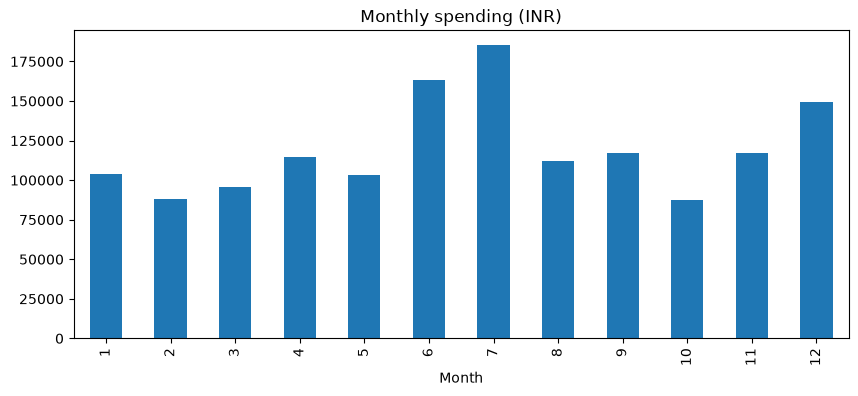

In [8]:
monthly_spending = df_expenses.groupby("Month")["Amount"].sum()

monthly_spending.plot(kind="bar", figsize=(10, 4), title="Monthly spending (INR)")
plt.show()

Amounts differ a lot between categories, so a single global threshold is not useful for anomaly detection. The anomaly model uses the amount relative to its own category.

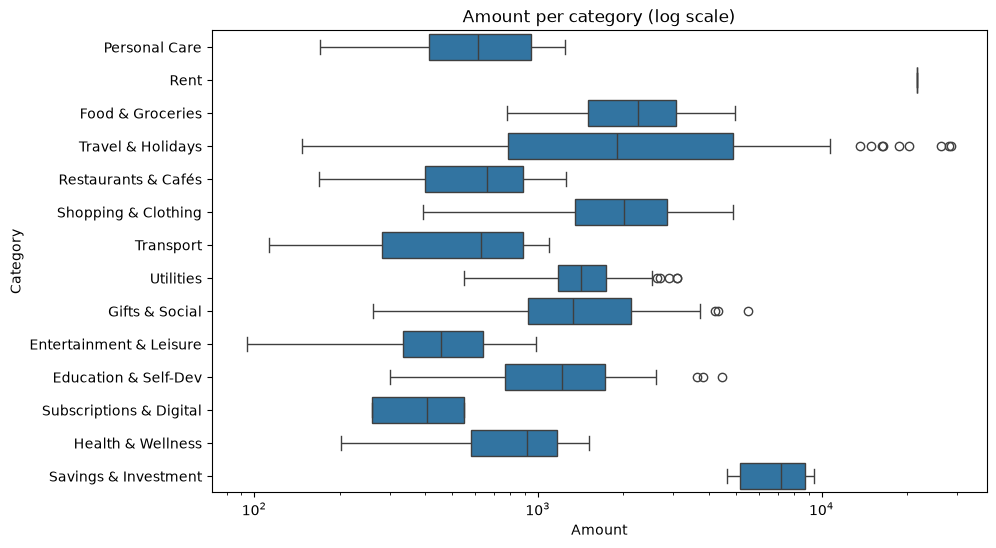

In [9]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_expenses, y="Category", x="Amount")
plt.xscale("log")
plt.title("Amount per category (log scale)")
plt.show()

In [10]:
df_expenses.groupby("Category")["Is Recurring"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False).head()

Category
Savings & Investment       1.0
Rent                       1.0
Subscriptions & Digital    1.0
Utilities                  1.0
Education & Self-Dev       0.0
Name: Is Recurring, dtype: float64

**Budgets vs spending**

`budget.csv` is in TND too. The first version of this notebook converted only the transactions, so every category-month looked overspent. Both sides are converted here.

In [11]:
budget_long = df_budget.melt(id_vars="Category", var_name="Month_Year", value_name="Budget")
budget_long["Month"] = pd.to_datetime(budget_long["Month_Year"], format="%B %Y").dt.month
budget_long["Budget"] = budget_long["Budget"] * TND_TO_INR

category_summary = df_expenses.groupby(["Category", "Month"])["Amount"].sum().reset_index()
merged_df = budget_long.merge(category_summary, on=["Category", "Month"], how="left")
merged_df["Amount"] = merged_df["Amount"].fillna(0)
merged_df["Overspent"] = (merged_df["Amount"] > merged_df["Budget"]).astype(int)
merged_df["Overspent"].value_counts()

Overspent
0    89
1    79
Name: count, dtype: int64

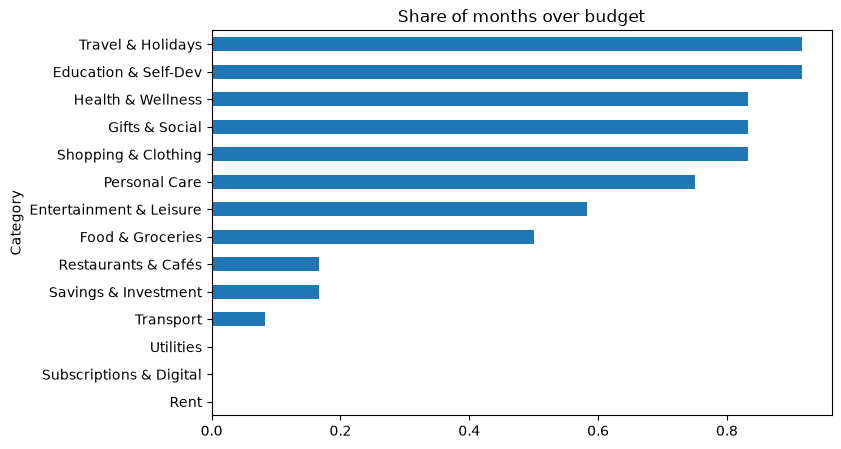

In [12]:
merged_df.groupby("Category")["Overspent"].mean().sort_values().plot(kind="barh", figsize=(8, 5), title="Share of months over budget")
plt.show()

The overspend model does not use the full-month amount (that is the label). It predicts end-of-month overspend from spend at day 7, 14 and 21. See `src/expense_tracker/features.py`.